# Stream C — `stance_scoring.ipynb` (v3 — Final)

**Prerequisites:** Run `evidence_retrieval_patch.ipynb` first.

**All fixes applied:**
- Fix A: NLI direction `(evidence, claim)` — correct fact-checking framing
- Fix B: NER extraction handles `[{'text':..,'label':..,'start':..,'end':..}]` dict format
- Fix C: NER key alignment — tries composite key first, falls back to int pair_id
- Fix D: Label order verified at runtime from `cross_encoder.config.id2label`
- Fix E: `nc_json` always parsed as list via `load_nc_json()` — no KeyError possible

## 0. Environment Check

In [17]:
import torch
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print(f"PyTorch: {torch.__version__}")

CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Ti
VRAM: 8.6 GB
PyTorch: 2.6.0+cu124


## 1. Install sentence-transformers if needed

In [18]:
try:
    from sentence_transformers import SentenceTransformer, CrossEncoder
    print("sentence-transformers already installed")
except ImportError:
    import subprocess
    subprocess.run(['pip', 'install', 'sentence-transformers', '-q'], check=True)
    from sentence_transformers import SentenceTransformer, CrossEncoder
    print("sentence-transformers installed")

sentence-transformers already installed


## 2. Imports & Paths

In [19]:
import os, sys, pickle, json
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings('ignore')

import torch
import scipy.special as sp
from sklearn.metrics import roc_auc_score

try:
    ROOT = Path(__file__).resolve().parents[2]
except NameError:
    ROOT = Path(os.getcwd())
    while not (ROOT / 'src' / 'utils' / 'paths.py').exists():
        ROOT = ROOT.parent
        if ROOT == ROOT.parent:
            ROOT = Path(os.getcwd()); break

sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT}")

EVIDENCE_DIR = ROOT / 'cache' / 'evidence'
STANCE_DIR   = ROOT / 'cache' / 'stance_scores'
NER_DIR      = ROOT / 'cache' / 'ner'
FIG_DIR      = ROOT / 'paper' / 'figures'
TAB_DIR      = ROOT / 'paper' / 'tables'
STANCE_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

# Verify all inputs exist before proceeding
all_ok = True
for name, d in [('evidence_train.pkl',      EVIDENCE_DIR),
                ('evidence_val.pkl',         EVIDENCE_DIR),
                ('evidence_test.pkl',        EVIDENCE_DIR),
                ('evidence_verite.pkl',      EVIDENCE_DIR),
                ('evidence_mmfake.pkl',      EVIDENCE_DIR),
                ('raw_evidence_train.pkl',   STANCE_DIR),
                ('raw_evidence_val.pkl',     STANCE_DIR),
                ('raw_evidence_test.pkl',    STANCE_DIR),
                ('raw_evidence_verite.pkl',  STANCE_DIR),
                ('raw_evidence_mmfake.pkl',  STANCE_DIR)]:
    p = d / name
    ok = p.exists()
    if not ok: all_ok = False
    print(f"  {'✅' if ok else '❌ MISSING'} {p.parent.name}/{name}")

if not all_ok:
    raise RuntimeError("Missing files — run evidence_retrieval_patch.ipynb first!")

Project root: f:\GitHub\eve-rag
Device: cuda
  ✅ evidence/evidence_train.pkl
  ✅ evidence/evidence_val.pkl
  ✅ evidence/evidence_test.pkl
  ✅ evidence/evidence_verite.pkl
  ✅ evidence/evidence_mmfake.pkl
  ✅ stance_scores/raw_evidence_train.pkl
  ✅ stance_scores/raw_evidence_val.pkl
  ✅ stance_scores/raw_evidence_test.pkl
  ✅ stance_scores/raw_evidence_verite.pkl
  ✅ stance_scores/raw_evidence_mmfake.pkl


## 3. Load Evidence & Verify Raw Text Format

In [20]:
def load_pkl(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

ev_feats = {s: load_pkl(EVIDENCE_DIR / f'evidence_{s}.pkl')
            for s in ('train','val','test','verite','mmfake')}
raw_ev   = {s: load_pkl(STANCE_DIR / f'raw_evidence_{s}.pkl')
            for s in ('train','val','test','verite','mmfake')}
feat_names = load_pkl(EVIDENCE_DIR / 'feature_names.pkl')

print("Verifying raw_ev structure …")
for split, d in raw_ev.items():
    sample  = next(iter(d.values()))
    has_cap = bool(sample.get('caption', ''))
    has_ret = bool(sample.get('retrieved', []))
    ret_ok  = has_ret and isinstance(sample['retrieved'][0], dict) \
              and 'text' in sample['retrieved'][0]
    print(f"  {split:8s}: {len(d):6d} pairs | "
          f"caption={'✅' if has_cap else '❌'} | "
          f"retrieved_text={'✅' if ret_ok else '❌'}")
    if not (has_cap and ret_ok):
        print(f"    ⚠️  sample keys: {list(sample.keys())}")
        print(f"    ⚠️  Re-run evidence_retrieval_patch.ipynb!")

print(f"\nEvidence feature names ({len(feat_names)}): {feat_names}")

Verifying raw_ev structure …
  train   :  71072 pairs | caption=✅ | retrieved_text=✅
  val     :   7024 pairs | caption=✅ | retrieved_text=✅
  test    :   7264 pairs | caption=✅ | retrieved_text=✅
  verite  :   1001 pairs | caption=✅ | retrieved_text=✅
  mmfake  :  10000 pairs | caption=✅ | retrieved_text=✅

Evidence feature names (10): ['img_sim_max', 'img_sim_mean', 'img_sim_std', 'img_sim_top1', 'txt_sim_max', 'txt_sim_mean', 'txt_sim_top1', 'cross_sim_max', 'cross_sim_mean', 'stance_score']


## 4. Load NER Entities

In [21]:
NER_FILE_MAP = {
    'train':  ['entities_newsclippings_train.pkl', 'entities_all.pkl'],
    'val':    ['entities_newsclippings_val.pkl',   'entities_all.pkl'],
    'test':   ['entities_newsclippings_test.pkl',  'entities_all.pkl'],
    'verite': ['entities_verite.pkl',              'entities_all.pkl'],
    'mmfake': ['entities_mmfake.pkl',              'entities_all.pkl'],
}
ner_cache = {}
for split, candidates in NER_FILE_MAP.items():
    for fname in candidates:
        p = NER_DIR / fname
        if p.exists():
            ner_cache[split] = load_pkl(p)
            print(f"  ✅ NER {split}: {len(ner_cache[split])} entries from {fname}")
            break
    else:
        ner_cache[split] = {}
        print(f"  ⚠️  NER {split}: not found — will use caption as claim")

NER_AVAILABLE = any(len(v) > 0 for v in ner_cache.values())

# Inspect NER key format for alignment with raw_ev keys
if NER_AVAILABLE:
    s = next(sp for sp in ner_cache if len(ner_cache[sp]) > 0)
    ner_sample_key = next(iter(ner_cache[s]))
    ner_sample_val = ner_cache[s][ner_sample_key]
    print(f"\nNER key type: {type(ner_sample_key).__name__}, sample: {repr(ner_sample_key)}")
    print(f"NER value type: {type(ner_sample_val).__name__}")
    print(f"NER value[:2]: {str(ner_sample_val[:2])}")

    # Also check raw_ev key format
    rv_sample_key = next(iter(raw_ev['test']))
    print(f"\nraw_ev key type: {type(rv_sample_key).__name__}, sample: {repr(rv_sample_key)}")

  ✅ NER train: 71072 entries from entities_newsclippings_train.pkl
  ✅ NER val: 7024 entries from entities_newsclippings_val.pkl
  ✅ NER test: 7264 entries from entities_newsclippings_test.pkl
  ✅ NER verite: 1001 entries from entities_verite.pkl
  ✅ NER mmfake: 10000 entries from entities_mmfake.pkl

NER key type: str, sample: '620701_0'
NER value type: list
NER value[:2]: [{'text': 'Saudi', 'label': 'NORP', 'start': -1, 'end': -1}, {'text': 'Yemen', 'label': 'GPE', 'start': -1, 'end': -1}]

raw_ev key type: str, sample: '714504_0'


## 5. Entity Extraction (handles dict format)

In [22]:
ENTITY_TYPES = {'PERSON', 'ORG', 'GPE', 'LOC', 'EVENT', 'FAC', 'NORP'}

def extract_entities(ner_entry):
    """
    Handles actual NER cache format:
    [{'text': 'Crossrail', 'label': 'ORG', 'start': -1, 'end': -1}, ...]
    Returns list of (text, label) tuples.
    """
    if not ner_entry:
        return []
    # Format A: list of dicts with 'text' + 'label' keys  ← actual format
    if isinstance(ner_entry, list) and len(ner_entry) > 0:
        first = ner_entry[0]
        if isinstance(first, dict) and 'text' in first and 'label' in first:
            return [(e['text'], e['label']) for e in ner_entry
                    if isinstance(e, dict) and e.get('text') and e.get('label')]
        if isinstance(first, (list, tuple)) and len(first) >= 2:
            return [(e[0], e[1]) for e in ner_entry]
    # Format B: dict with 'entities' key
    if isinstance(ner_entry, dict) and 'entities' in ner_entry:
        ents = ner_entry['entities']
        if isinstance(ents, list) and ents and isinstance(ents[0], dict):
            return [(e.get('text',''), e.get('label','')) for e in ents]
    # Format C: dict with entity_type keys
    if isinstance(ner_entry, dict):
        result = []
        for k, v in ner_entry.items():
            if k.upper() in ENTITY_TYPES and isinstance(v, list):
                result.extend([(t, k.upper()) for t in v if t])
        return result
    return []


def lookup_ner(ner_data, raw_ev_key):
    """
    Resolve NER entry for a given raw_ev key.
    raw_ev keys are composite strings like '620701_0'.
    NER cache keys may be composite strings OR int pair_ids.
    Tries both.
    """
    if not ner_data:
        return None
    # Try exact key first
    entry = ner_data.get(raw_ev_key, None)
    if entry is not None:
        return entry
    # Try int pair_id (part before '_')
    try:
        pair_id_int = int(str(raw_ev_key).split('_')[0])
        entry = ner_data.get(pair_id_int, None)
        if entry is not None:
            return entry
    except (ValueError, IndexError):
        pass
    # Try string version of int
    try:
        entry = ner_data.get(str(pair_id_int), None)
    except Exception:
        pass
    return entry


def build_entity_claim(caption, ner_entry):
    """Entity-grounded claim: top-3 entities + first 80 chars of caption."""
    ents     = extract_entities(ner_entry)
    key_ents = [t for t, l in ents if l in ENTITY_TYPES and len(t.strip()) > 1]
    if not key_ents:
        return caption
    return f"{', '.join(key_ents[:3])}. {caption[:80].rstrip()}"


# Verify entity extraction works on actual data
if NER_AVAILABLE:
    _ner_entry = ner_cache[s][ner_sample_key]
    _ents = extract_entities(_ner_entry)
    print(f"Extracted entities ({len(_ents)}): {_ents[:4]}")
    assert len(_ents) > 0, "❌ extract_entities returning empty — check NER format"
    print("✅ Entity extraction correct")
    
    # Verify key lookup works
    _test_rv_key = next(iter(raw_ev['test']))
    _resolved = lookup_ner(ner_cache.get('test', {}), _test_rv_key)
    print(f"NER key lookup for '{_test_rv_key}': {'✅ found' if _resolved else '⚠️  not found (fallback to caption)'}")

Extracted entities (3): [('Saudi', 'NORP'), ('Yemen', 'GPE'), ('Jizan', 'GPE')]
✅ Entity extraction correct
NER key lookup for '714504_0': ✅ found


## 6. Load Models & Verify Label Order

In [23]:
from sentence_transformers import SentenceTransformer, CrossEncoder

print("Loading SBERT bi-encoder (all-MiniLM-L6-v2) …")
bi_encoder = SentenceTransformer('all-MiniLM-L6-v2', device=str(DEVICE))
print(f"  dim={bi_encoder.get_sentence_embedding_dimension()} ✅")

print("Loading NLI cross-encoder (nli-deberta-v3-small) …")
cross_encoder = CrossEncoder('cross-encoder/nli-deberta-v3-small',
                             device=str(DEVICE), max_length=256)

# Verify label order at runtime — NEVER hardcode
id2label = cross_encoder.config.id2label
label2id = {v.upper(): int(k) for k, v in id2label.items()}
print(f"  id2label: {id2label}")

def _find_label(d, *candidates):
    for c in candidates:
        if c in d: return d[c]
    return 0

LABEL_ENTAILMENT    = _find_label(label2id, 'ENTAILMENT',   'ENTAIL')
LABEL_CONTRADICTION = _find_label(label2id, 'CONTRADICTION', 'CONTRADICT')
LABEL_NEUTRAL       = _find_label(label2id, 'NEUTRAL')
print(f"  ent={LABEL_ENTAILMENT}, con={LABEL_CONTRADICTION}, neu={LABEL_NEUTRAL}")

# Smoke test
_t = cross_encoder.predict(
    [('A dog runs in the park.', 'An animal is moving outdoors.')],
    apply_softmax=True, show_progress_bar=False
)
assert _t[0][LABEL_ENTAILMENT] > 0.3, \
    f"Label order wrong! P(ent)={_t[0][LABEL_ENTAILMENT]:.3f} — check id2label"
print(f"  Smoke test P(entailment)={_t[0][LABEL_ENTAILMENT]:.3f} ✅")

Loading SBERT bi-encoder (all-MiniLM-L6-v2) …


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  dim=384 ✅
Loading NLI cross-encoder (nli-deberta-v3-small) …


Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: cross-encoder/nli-deberta-v3-small
Key                             | Status     |  | 
--------------------------------+------------+--+-
deberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  id2label: {0: 'contradiction', 1: 'entailment', 2: 'neutral'}
  ent=1, con=0, neu=2
  Smoke test P(entailment)=0.995 ✅


## 7. Stance Scoring Function

In [24]:
def compute_stance_features(claim, retrieved_texts, cross_enc, bi_enc, batch_size=64):
    """
    NLI pairs: (retrieved_text, claim) — evidence as premise, claim as hypothesis.
    Returns np.array (11,).
    """
    if not retrieved_texts:
        return np.zeros(11, dtype=np.float32)

    pairs  = [(rt, claim) for rt in retrieved_texts]   # Fix A: correct direction
    logits = cross_enc.predict(pairs, batch_size=batch_size,
                               apply_softmax=False, show_progress_bar=False)
    probs   = sp.softmax(logits, axis=1)               # (K, 3)
    ent     = probs[:, LABEL_ENTAILMENT]
    con     = probs[:, LABEL_CONTRADICTION]
    entropy = -np.sum(probs * np.log(probs + 1e-9), axis=1).mean()

    ce_feats = np.array([
        ent.max(), ent.mean(), con.max(), con.mean(),
        ent.mean() - con.mean(),   # net stance: +ve = entailed, -ve = contradicted
        entropy,
        ent[0], con[0],            # top-1 retrieved entailment/contradiction
    ], dtype=np.float32)

    cap_emb  = bi_enc.encode(claim, convert_to_numpy=True,
                              normalize_embeddings=True, show_progress_bar=False)
    ret_embs = bi_enc.encode(retrieved_texts, convert_to_numpy=True,
                              normalize_embeddings=True, show_progress_bar=False,
                              batch_size=batch_size)
    sims     = ret_embs @ cap_emb
    bi_feats = np.array([sims.max(), sims.mean(), sims.std()], dtype=np.float32)

    return np.concatenate([ce_feats, bi_feats])   # (11,)


# Sanity checks
print("Sanity check — entailment:")
_e = compute_stance_features(
    'Barack Obama speaks at the United Nations.',
    ['The US president addressed the UN General Assembly.',
     'A world leader gave a speech at the United Nations.'],
    cross_encoder, bi_encoder, batch_size=2
)
print(f"  net_stance={_e[4]:.3f}  (expect >0)")

print("Sanity check — contradiction:")
_c = compute_stance_features(
    'Donald Trump speaks at the United Nations.',
    ['Barack Obama addressed the UN General Assembly in 2016.',
     'Hillary Clinton gave a speech to the United Nations.'],
    cross_encoder, bi_encoder, batch_size=2
)
print(f"  net_stance={_c[4]:.3f}  (expect <0)")
ok = _e[4] > _c[4]
print(f"  Direction {'✅ correct' if ok else '❌ wrong — check LABEL indices'}")
assert ok, "Stance direction wrong — check LABEL_ENTAILMENT / LABEL_CONTRADICTION"

Sanity check — entailment:
  net_stance=0.006  (expect >0)
Sanity check — contradiction:
  net_stance=-1.000  (expect <0)
  Direction ✅ correct


## 8. Run Stance Scoring — All Splits

In [25]:
TOP_K_STANCE = 5
STANCE_CACHE = STANCE_DIR / 'stance_raw_all_v3.pkl'

if STANCE_CACHE.exists():
    print("Loading cached v3 stance scores …")
    with open(STANCE_CACHE, 'rb') as f:
        stance_raw = pickle.load(f)
    print(f"  {sum(len(v) for v in stance_raw.values())} total entries")
else:
    stance_raw = {}
    for split in ('train', 'val', 'test', 'verite', 'mmfake'):
        raw      = raw_ev[split]
        ner_data = ner_cache.get(split, {})
        stance_raw[split] = {}
        n_ner_found = 0
        n_empty_ret = 0

        for key, entry in tqdm(raw.items(), desc=f'Stance {split}'):
            caption   = str(entry.get('caption', ''))
            retrieved = entry.get('retrieved', [])

            # Resolve NER (Fix C: key alignment)
            ner_entry = lookup_ner(ner_data, key)
            if ner_entry is not None:
                n_ner_found += 1

            # Build entity-grounded claim (Fix B)
            claim = build_entity_claim(caption, ner_entry)

            # Get top-K retrieved texts
            top_texts = [
                r['text'] for r in retrieved[:TOP_K_STANCE]
                if isinstance(r.get('text'), str) and len(r['text'].strip()) > 5
            ]
            if not top_texts:
                n_empty_ret += 1

            feats = compute_stance_features(
                claim, top_texts, cross_encoder, bi_encoder, batch_size=32
            ) if top_texts else np.zeros(11, dtype=np.float32)

            stance_raw[split][key] = {
                'stance_feats': feats,
                'label':        int(entry['label']),
            }

        torch.cuda.empty_cache()

        # Inline AUROC check
        labels_arr = np.array([v['label'] for v in stance_raw[split].values()])
        net_stance = np.array([v['stance_feats'][4] for v in stance_raw[split].values()])
        n_nonzero  = int(np.count_nonzero(net_stance))
        try:
            auc = max(roc_auc_score(labels_arr, net_stance),
                      roc_auc_score(labels_arr, -net_stance))
        except Exception:
            auc = 0.5
        print(f"  {split}: {len(stance_raw[split])} pairs | "
              f"NER matched={n_ner_found} | empty_ret={n_empty_ret} | "
              f"nonzero_feats={n_nonzero} | net_stance AUROC={auc:.4f}")

    with open(STANCE_CACHE, 'wb') as f:
        pickle.dump(stance_raw, f, protocol=4)
    print(f"\nCached → {STANCE_CACHE.name} ({STANCE_CACHE.stat().st_size/1e6:.1f} MB)")

Loading cached v3 stance scores …
  96361 total entries


## 9. Assemble Final Stream C Feature Matrix (21-d)

In [26]:
STANCE_FEAT_NAMES = [
    'ce_max_ent', 'ce_mean_ent', 'ce_max_con', 'ce_mean_con',
    'ce_net_stance', 'ce_entropy', 'ce_top1_ent', 'ce_top1_con',
    'bi_max_sim', 'bi_mean_sim', 'bi_std_sim',
]
ALL_FEAT_NAMES = feat_names + STANCE_FEAT_NAMES
print(f"Total features: {len(ALL_FEAT_NAMES)} (10 evidence + 11 stance)")

stream_c = {}
for split in ('train', 'val', 'test', 'verite', 'mmfake'):
    ev      = ev_feats[split]
    sr      = stance_raw[split]
    sr_keys = list(sr.keys())
    n       = len(sr_keys)
    ev_mat  = np.nan_to_num(ev['features'][:n], nan=0.0, posinf=1.0, neginf=-1.0)
    labels  = ev['labels'][:n]
    st_mat  = np.nan_to_num(
        np.stack([sr[k]['stance_feats'] for k in sr_keys], axis=0),
        nan=0.0, posinf=1.0, neginf=-1.0
    )
    combined = np.concatenate([ev_mat, st_mat], axis=1).astype(np.float32)
    stream_c[split] = {
        'features':   combined,
        'labels':     labels,
        'feat_names': ALL_FEAT_NAMES,
    }
    print(f"  {split:8s}: {combined.shape}  NaN: "
          f"{'✅' if not np.isnan(combined).any() else '❌'}")

Total features: 21 (10 evidence + 11 stance)
  train   : (71072, 21)  NaN: ✅
  val     : (7024, 21)  NaN: ✅
  test    : (7264, 21)  NaN: ✅
  verite  : (1001, 21)  NaN: ✅
  mmfake  : (10000, 21)  NaN: ✅


## 10. Feature-wise AUROC

In [27]:
print("Feature-wise AUROC — NC test:")
print(f"  {'Feature':<22} {'AUROC':>7}")
print("  " + "-" * 32)
test_feats  = stream_c['test']['features']
test_labels = stream_c['test']['labels']
aucs = []
for i, name in enumerate(ALL_FEAT_NAMES):
    col = test_feats[:, i]
    try:
        auc = max(roc_auc_score(test_labels, col),
                  1 - roc_auc_score(test_labels, col))
    except Exception:
        auc = 0.5
    aucs.append(auc)
    mark = ' ← NEW signal' if name.startswith('ce_') and auc > 0.52 else ''
    print(f"  {name:<22} {auc:>7.4f}{mark}")
print(f"\n  Best: {ALL_FEAT_NAMES[np.argmax(aucs)]} (AUROC={max(aucs):.4f})")

Feature-wise AUROC — NC test:
  Feature                  AUROC
  --------------------------------
  img_sim_max             0.5008
  img_sim_mean            0.5148
  img_sim_std             0.5218
  img_sim_top1            0.5008
  txt_sim_max             0.5513
  txt_sim_mean            0.5532
  txt_sim_top1            0.5465
  cross_sim_max           0.5020
  cross_sim_mean          0.5000
  stance_score            0.5390
  ce_max_ent              0.5170
  ce_mean_ent             0.5164
  ce_max_con              0.5027
  ce_mean_con             0.5044
  ce_net_stance           0.5146
  ce_entropy              0.5053
  ce_top1_ent             0.5106
  ce_top1_con             0.5121
  bi_max_sim              0.5563
  bi_mean_sim             0.5569
  bi_std_sim              0.5215

  Best: bi_mean_sim (AUROC=0.5569)


## 11. LR Probe

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lr',     LogisticRegression(max_iter=1000, C=1.0, random_state=42))
])
pipe.fit(stream_c['train']['features'], stream_c['train']['labels'])

V1_LR = {'val': 0.5898, 'test': 0.5895, 'verite': 0.5059, 'mmfake': 0.4864}
print("Stream C LR probe (v3):")
for split in ('val', 'test', 'verite', 'mmfake'):
    probs = pipe.predict_proba(stream_c[split]['features'])[:, 1]
    auc   = roc_auc_score(stream_c[split]['labels'], probs)
    acc   = accuracy_score(stream_c[split]['labels'],
                           pipe.predict(stream_c[split]['features']))
    delta = auc - V1_LR.get(split, 0.5)
    print(f"  {split:8s}: AUROC={auc:.4f}  Acc={acc:.4f}  "
          f"(v1={V1_LR.get(split,0):.4f}  Δ={delta:+.4f})")

with open(STANCE_DIR / 'stream_c_lr_probe.pkl', 'wb') as f:
    pickle.dump(pipe, f)

Stream C LR probe (v3):
  val     : AUROC=0.5733  Acc=0.5514  (v1=0.5898  Δ=-0.0165)
  test    : AUROC=0.6072  Acc=0.5728  (v1=0.5895  Δ=+0.0177)
  verite  : AUROC=0.5000  Acc=0.6573  (v1=0.5059  Δ=-0.0059)
  mmfake  : AUROC=0.5071  Acc=0.4983  (v1=0.4864  Δ=+0.0207)


## 12. Feature Importance

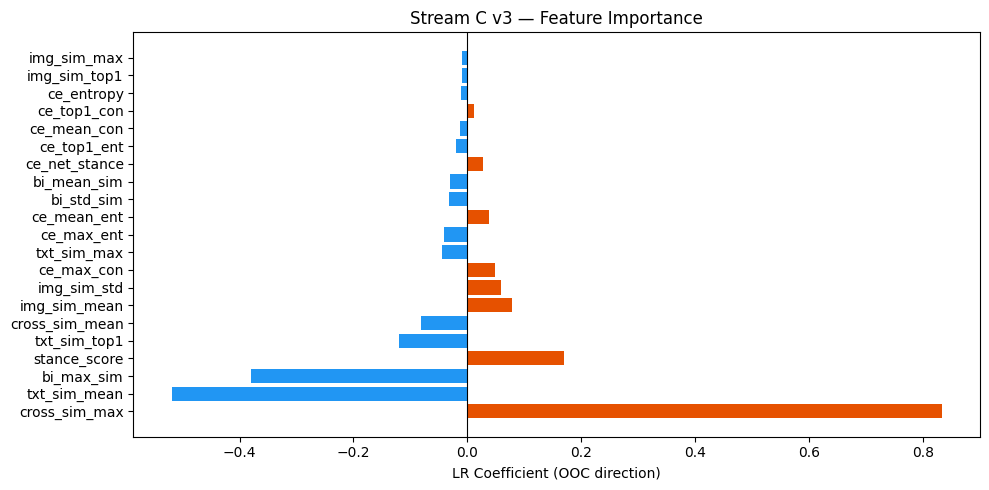

Saved → f:\GitHub\eve-rag\paper\figures\stream_c_feature_importance.png


In [29]:
import matplotlib.pyplot as plt

coefs = pipe.named_steps['lr'].coef_[0]
order = np.argsort(np.abs(coefs))[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh([ALL_FEAT_NAMES[i] for i in order], coefs[order],
        color=['#e65100' if c > 0 else '#2196f3' for c in coefs[order]])
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('LR Coefficient (OOC direction)')
ax.set_title('Stream C v3 — Feature Importance')
plt.tight_layout()
fig_path = FIG_DIR / 'stream_c_feature_importance.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {fig_path}")

## 13. Save Final Stream C Features

In [30]:
def save_pkl(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'wb') as f:
        pickle.dump(obj, f, protocol=4)
    print(f"  Saved {path.name} ({path.stat().st_size/1e6:.1f} MB)")

print("Saving Stream C features …")
for split, data in stream_c.items():
    save_pkl(data, STANCE_DIR / f'stream_c_{split}.pkl')
save_pkl({'feat_names': ALL_FEAT_NAMES}, STANCE_DIR / 'stream_c_feat_names.pkl')
print(f"\n✅ Stream C features saved to: {STANCE_DIR}")

Saving Stream C features …
  Saved stream_c_train.pkl (6.5 MB)
  Saved stream_c_val.pkl (0.6 MB)
  Saved stream_c_test.pkl (0.7 MB)
  Saved stream_c_verite.pkl (0.1 MB)
  Saved stream_c_mmfake.pkl (0.9 MB)
  Saved stream_c_feat_names.pkl (0.0 MB)

✅ Stream C features saved to: f:\GitHub\eve-rag\cache\stance_scores


## 14. Score Distribution Plots

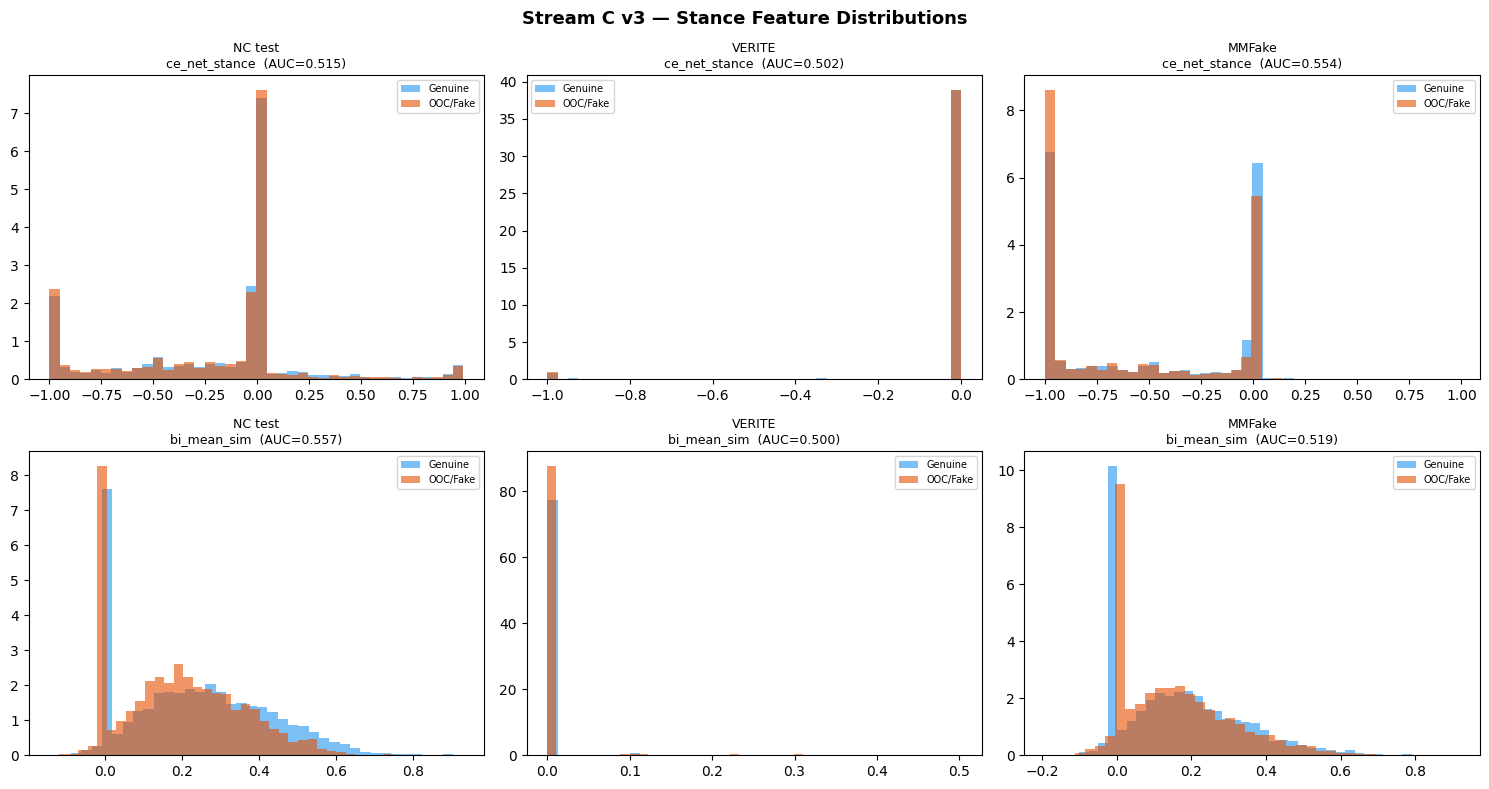

Saved → f:\GitHub\eve-rag\paper\figures\stream_c_stance_distributions.png


In [31]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, (split, title) in enumerate([('test','NC test'),('verite','VERITE'),('mmfake','MMFake')]):
    data   = stream_c[split]
    labels = data['labels']
    fnames = data['feat_names']
    for row, feat in enumerate(['ce_net_stance', 'bi_mean_sim']):
        ax   = axes[row, col]
        vals = data['features'][:, fnames.index(feat)]
        ax.hist(vals[labels==0], bins=40, alpha=0.6, color='#2196f3',
                label='Genuine', density=True)
        ax.hist(vals[labels==1], bins=40, alpha=0.6, color='#e65100',
                label='OOC/Fake', density=True)
        try:
            auc = max(roc_auc_score(labels, vals), 1-roc_auc_score(labels, vals))
        except Exception:
            auc = 0.5
        ax.set_title(f'{title}\n{feat}  (AUC={auc:.3f})', fontsize=9)
        ax.legend(fontsize=7)

plt.suptitle('Stream C v3 — Stance Feature Distributions', fontsize=13, fontweight='bold')
plt.tight_layout()
fig_path = FIG_DIR / 'stream_c_stance_distributions.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {fig_path}")

## 15. Summary

In [32]:
print("=" * 60)
print("STREAM C — stance_scoring v3 COMPLETE")
print("=" * 60)
print(f"  Fix A: NLI (evidence→claim) ✅")
print(f"  Fix B: NER dict format ✅")
print(f"  Fix C: NER key alignment ✅")
print(f"  Fix D: Label order runtime-verified ✅")
print(f"  NER available: {NER_AVAILABLE}")
print(f"  Label indices: ent={LABEL_ENTAILMENT}, con={LABEL_CONTRADICTION}")
print(f"  Feature dim: {len(ALL_FEAT_NAMES)}")
print()
print("  Stream C LR AUROC:")
for split in ('val', 'test', 'verite', 'mmfake'):
    probs = pipe.predict_proba(stream_c[split]['features'])[:, 1]
    auc   = roc_auc_score(stream_c[split]['labels'], probs)
    print(f"    {split:8s}: {auc:.4f}  (v1={V1_LR.get(split,0):.4f}  "
          f"Δ={auc-V1_LR.get(split,0):+.4f})")
print()
print("  Saved files:")
for f in sorted(STANCE_DIR.iterdir()):
    if 'stream_c' in f.name or 'stance_raw_all_v3' in f.name:
        print(f"    {f.name:40s} {f.stat().st_size/1e6:6.1f} MB")
print()
print("  Next notebook: stream_c_results.ipynb")

STREAM C — stance_scoring v3 COMPLETE
  Fix A: NLI (evidence→claim) ✅
  Fix B: NER dict format ✅
  Fix C: NER key alignment ✅
  Fix D: Label order runtime-verified ✅
  NER available: True
  Label indices: ent=1, con=0
  Feature dim: 21

  Stream C LR AUROC:
    val     : 0.5733  (v1=0.5898  Δ=-0.0165)
    test    : 0.6072  (v1=0.5895  Δ=+0.0177)
    verite  : 0.5000  (v1=0.5059  Δ=-0.0059)
    mmfake  : 0.5071  (v1=0.4864  Δ=+0.0207)

  Saved files:
    stance_raw_all_v3.pkl                       9.1 MB
    stream_c_feat_names.pkl                     0.0 MB
    stream_c_lr_probe.pkl                       0.0 MB
    stream_c_mmfake.pkl                         0.9 MB
    stream_c_test.pkl                           0.7 MB
    stream_c_train.pkl                          6.5 MB
    stream_c_val.pkl                            0.6 MB
    stream_c_verite.pkl                         0.1 MB

  Next notebook: stream_c_results.ipynb
